In [ ]:
# Packages and CSV Reader 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
from sqlalchemy import create_engine 

data = pd.read_csv(r"../data/candidates.csv", delimiter = ';')

data.info()

In [ ]:
data = data.rename(columns=
{
"First Name": "first_name", 
"Last Name": "last_name", 
"Email": "email", 
"Application Date": "application_date",
"Country": "country",
"YOE": "yoe", 
"Seniority" : "seniority",
"Technology": "technology", 
"Code Challenge Score": "code_challenge_score", 
"Technical Interview Score": "technical_interview_score"
})

data['application_date'] = pd.to_datetime(data['application_date'], format = 'ISO8601')
data.head()

In [ ]:
# postgres connection 
username = 'postgres'
password = '1234'
host = 'localhost'
port = '5432'
database = 'candidates_db'

engine = create_engine(
    f"postgresql+psycopg2://{username}:{password}@{host}:{port}/{database}"
)


In [ ]:
print("Persisting in PostgreSQL database")
data.to_sql('candidates', engine, if_exists = 'replace', index = False)

In [ ]:
selected = pd.read_sql("SELECT * FROM candidates", engine)

selected.head()

In [ ]:
hired = pd.read_sql("SELECT * FROM candidates WHERE code_challenge_score >= 7 AND technical_interview_score >= 7", engine)

hired.head()

In [ ]:
print("Hires by technology (pie chart)")

hires_by_tech = hired['technology'].value_counts()

plt.figure(figsize=(10,8))

plt.pie(
    hires_by_tech, 
    labels=hires_by_tech.index,
    autopct='%1.1f%%',
    startangle = 90

)

plt.title('Hires by Technology')
plt.tight_layout()
plt.show()

In [ ]:
print("Hires by year (horizontal bar chart)")

hired = pd.read_sql(
"""SELECT *, 
    CAST(EXTRACT(YEAR FROM application_date) AS TEXT) AS year 
    FROM candidates 
    WHERE code_challenge_score >= 7 AND technical_interview_score >= 7

""", engine)


hires_by_year = hired['year'].value_counts().sort_index()

plt.figure(figsize=(10,8))

sns.barplot(
    x=hires_by_year.values,
    y=hires_by_year.index,
    orient='h'

)
plt.xlabel("Number of Hires")
plt.ylabel("Years")

plt.title('Hires by Year')
plt.tight_layout()
plt.show()

In [ ]:
print("Hires by seniority (bar chart)")

hires_by_senior = hired['seniority'].value_counts()

plt.figure(figsize=(10,6))

sns.barplot(
    x=hires_by_senior.values,
    y=hires_by_senior.index,
)

plt.xlabel("Number of Hires")
plt.ylabel("Seniorty")

plt.xticks(rotation=45)
plt.title('Hires by Seniority')
plt.tight_layout()
plt.show()


Hires by country over the years (USA, Brazil, Colombia, and Ecuador only)(multiline chart)


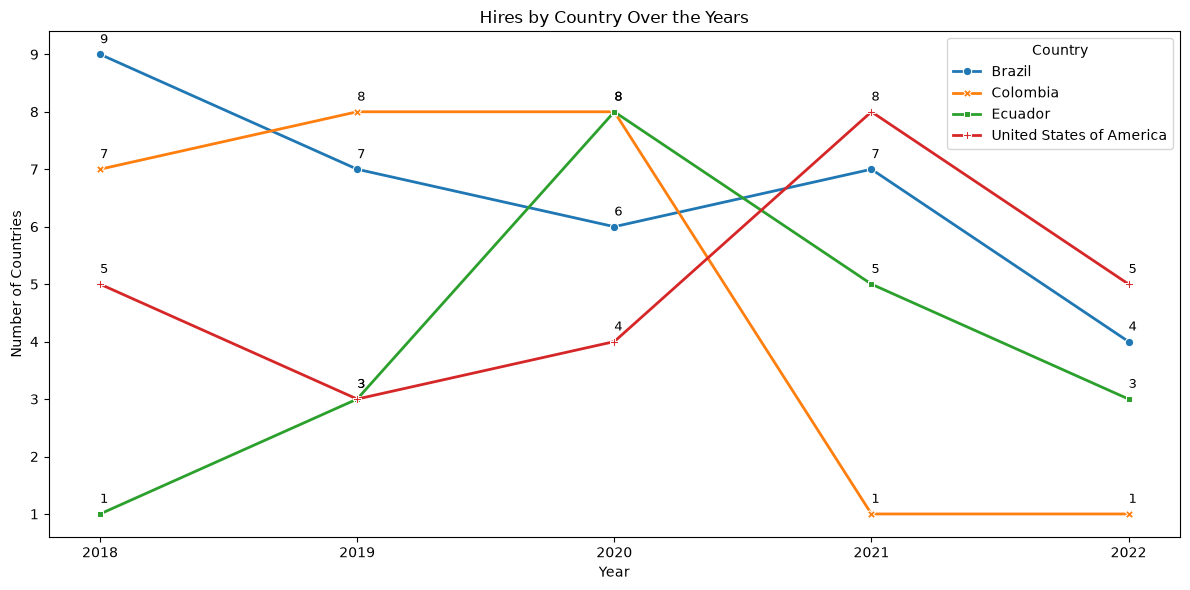

In [32]:
print("Hires by country over the years (USA, Brazil, Colombia, and Ecuador only)(multiline chart)")

selected = pd.read_sql("""
    SELECT
    country, 
    CAST(EXTRACT(YEAR FROM application_date) AS TEXT) AS year,
    COUNT(*) AS hires
    FROM candidates 
    WHERE code_challenge_score >= 7 AND technical_interview_score >= 7
    AND country in ('United States of America', 'Brazil', 'Colombia', 'Ecuador')
    GROUP BY country, year
    ORDER BY country, year;

""",engine)

country_year_pivot = selected.pivot(
    index='year',
    columns='country', 
    values='hires'
)

plt.figure(figsize=(12,6))

ax = sns.lineplot(
    data=country_year_pivot,
    markers=True, 
    dashes=False, 
    linewidth=2

)

for line in ax.lines:
    for x, y in zip(line.get_xdata(), line.get_ydata()):
        ax.annotate(
            f'{int(y)}',
            (x,y),
            textcoords= 'offset points',
            xytext=(0,8),
            fontsize=9

        )

plt.title('Hires by Country Over the Years')
plt.xlabel('Year')
plt.ylabel('Number of Countries')
plt.legend(title='Country')
plt.xticks(country_year_pivot.index)

plt.tight_layout()
plt.show()
